In [ ]:
# !pip install hmmlearn, yfinance, scipy, statsmodels -- quiet

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from hmmlearn.hmm import GaussianHMM
from scipy.stats import rankdata, norm
from scipy.optimize import minimize
from utils import fetch_binance_data
import yfinance as yf
import random
random.seed(42)
np.random.seed(42)

In [ ]:
# === Load and Align Data ===
tickers = ['ETHUSDT', 'BNBUSDT', 'TRXUSDT', 'BTCUSDT', 'DOGEUSDT', 'BTCDOMUSDT', 'XAUT-USD']

data_frames = []
asset_names = []
for ticker in tickers:
    if ticker == 'XAUT-USD':
        df = yf.download(ticker, period='max').T.droplevel(1).T
        df.index = pd.to_datetime(df.index, utc=True)
        df = df[['Open', 'High', 'Low', 'Close', 'Volume']]
        df.columns = ['open', 'high', 'low', 'close', 'volume']
    else:
        df = fetch_binance_data(ticker, kline_type='futures', interval='1d', years=5).set_index('open_time')
    data_frames.append(df)
    asset_names.append(ticker)

# Align all data
min_index = data_frames[0].index
for df in data_frames[1:]:
    min_index = min_index.intersection(df.index)
for i in range(len(data_frames)):
    data_frames[i] = data_frames[i].reindex(min_index)

# Calculate returns
returns = pd.DataFrame({
    asset_names[i]: df['close'].pct_change() for i, df in enumerate(data_frames)
}).dropna()

YF.download() has changed argument auto_adjust default to True


[*********************100%***********************]  1 of 1 completed



In [ ]:
# === Utility functions ===
def empirical_cdf(x):
    return rankdata(x) / (len(x) + 1)

def get_max_sharpe_weights(mean_ret, cov):
    n = len(mean_ret)
    def neg_sharpe(w):
        port_return = w @ mean_ret
        port_vol = np.sqrt(w @ cov @ w)
        return -port_return / port_vol if port_vol != 0 else 1e6
    x0 = np.ones(n) / n
    bounds = [(0.0, 0.9)] * n
    cons = {'type': 'eq', 'fun': lambda w: np.sum(w) - 1}
    res = minimize(neg_sharpe, x0, bounds=bounds, constraints=cons)
    return res.x if res.success else x0

In [ ]:
n_regimes = 3
rebalance_period = 30
asset_cols = returns.columns.tolist()

returns = returns.dropna()
features = returns[asset_cols].copy()

strategy_returns = []
regimes = []
weights_df = pd.DataFrame(np.nan, index=returns.index, columns=asset_cols)
last_weights = np.ones(len(asset_cols)) / len(asset_cols)
next_regime = 0

date = []
kelly_tracker = []

for t in range(n_regimes * 100, len(returns)):
    if t % rebalance_period == 0:
        train_data = features.iloc[:t].copy()

        hmm = GaussianHMM(n_components=n_regimes, covariance_type="full", n_iter=1500, random_state=42)
        hmm.fit(train_data)
        hidden_states = hmm.predict(train_data)
        train_data['Regime'] = hidden_states

        current_state = hidden_states[-1]
        next_state_probs = hmm.transmat_[current_state]
        next_regime = np.argmax(next_state_probs)

        regime_data = train_data[train_data['Regime'] == next_regime]
        U = regime_data[asset_cols].apply(empirical_cdf)
        copula_corr = np.corrcoef(U.T)

        rng = np.random.default_rng(seed=42)
        Z = rng.multivariate_normal(mean=np.zeros(len(asset_cols)), cov=copula_corr, size=10000)

        U_sim = norm.cdf(Z)
        sim_returns = pd.DataFrame({
            col: np.quantile(returns[col], U_sim[:, i]) for i, col in enumerate(asset_cols)
        })

        mu = sim_returns.mean().values
        cov = sim_returns.cov().values
        last_weights = get_max_sharpe_weights(mu, cov)
        port_e_mu = mu @ last_weights * 252

        real_rets = returns.iloc[:t]
        cov_ = real_rets[-30:].cov().values
        real_port_sigma = np.sqrt(np.dot(last_weights, np.dot(cov_, last_weights))) * 16

        kelly_fraction = port_e_mu / 2 / real_port_sigma if real_port_sigma != 0 else 1.0
        kelly_fraction = np.clip(kelly_fraction, 0.0, 1)
        kelly_tracker.append(kelly_fraction)
        date.append(regime_data.index[-1])
        weights_df.iloc[t] = last_weights

    ret = returns.iloc[t][asset_cols].values @ last_weights
    strategy_returns.append(ret)
    regimes.append(next_regime)

Model is not converging.  Current: 6070.493076750997 is not greater than 6070.502599754931. Delta is -0.009523003934191365
Model is not converging.  Current: 6615.0878877625555 is not greater than 6615.110178214252. Delta is -0.022290451696790115
Model is not converging.  Current: 7759.066395506352 is not greater than 7832.123426583696. Delta is -73.05703107734371
Model is not converging.  Current: 10079.163218093136 is not greater than 10079.263190783251. Delta is -0.0999726901154645
Model is not converging.  Current: 10680.950341277714 is not greater than 10681.012218955284. Delta is -0.06187767757000984
Model is not converging.  Current: 11315.632582380631 is not greater than 11315.676744641083. Delta is -0.04416226045213989
Model is not converging.  Current: 11945.423485178571 is not greater than 11945.485396447142. Delta is -0.06191126857083873
Model is not converging.  Current: 13136.449565619698 is not greater than 13136.512533213703. Delta is -0.06296759400538576
Model is not c

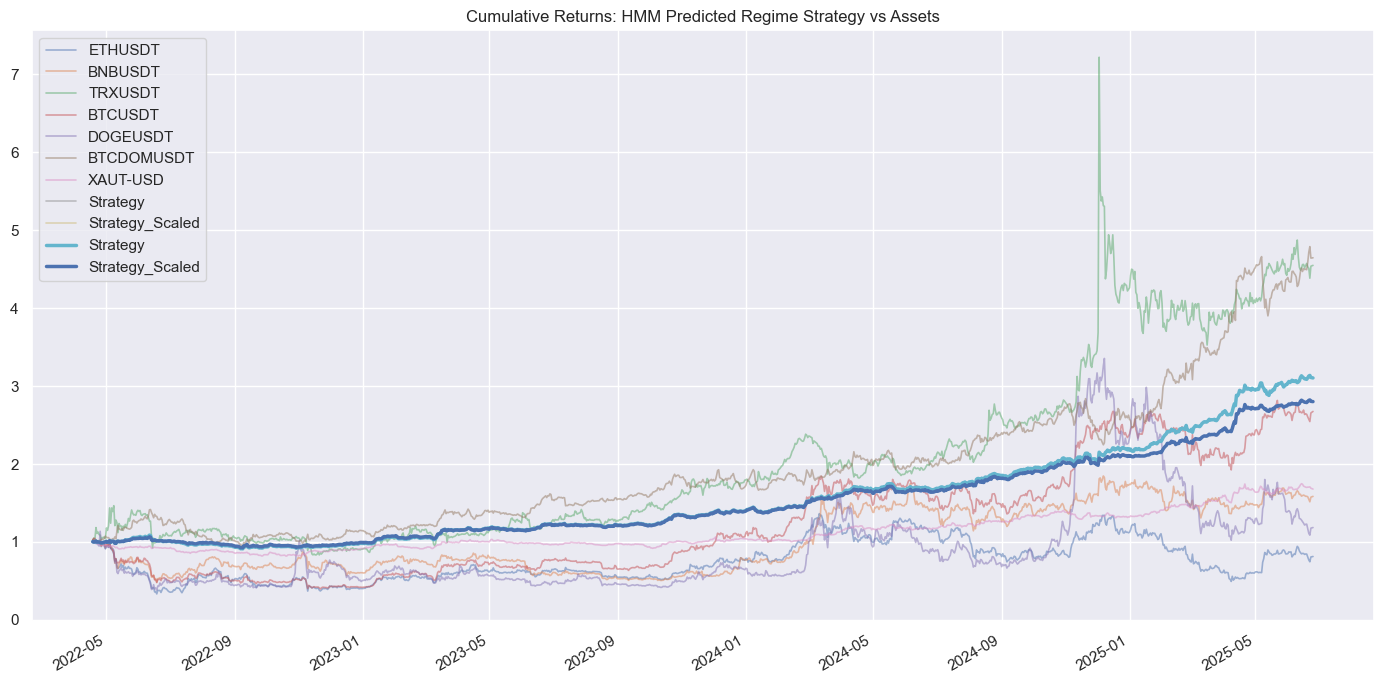

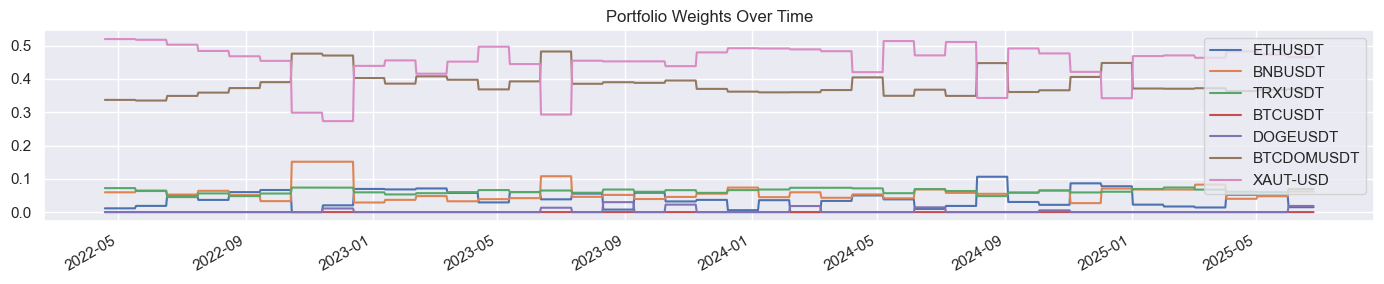

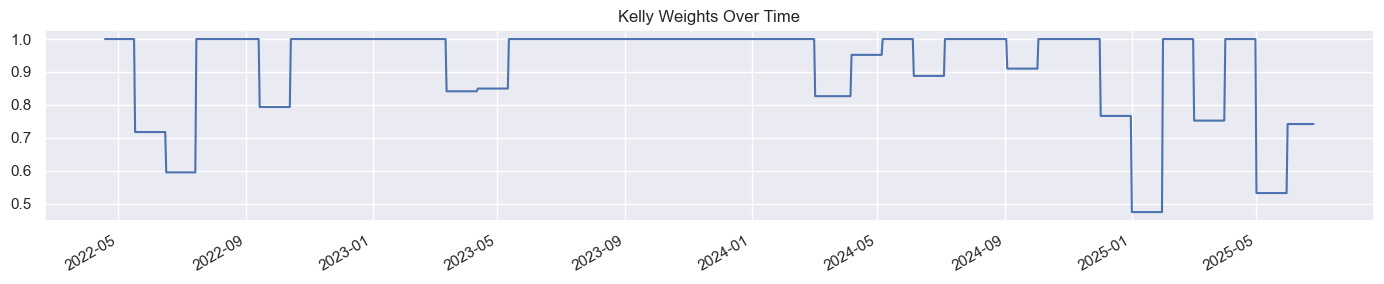

In [ ]:
kelly_size = pd.Series(kelly_tracker, index=date)
kelly_size = kelly_size.reindex(returns.index).ffill().fillna(1)
returns = returns[-len(strategy_returns):]

returns['Strategy'] = strategy_returns
returns['Regime'] = regimes
returns['Kelly'] = kelly_size
returns['Strategy_Scaled'] = returns['Strategy'] * returns['Kelly']

weights_df = weights_df.ffill().iloc[n_regimes * 100:]
returns = returns.join(weights_df.add_suffix('_w'))

# --- Plot cumulative returns ---
cumulative = (1 + returns[asset_cols + ['Strategy', 'Strategy_Scaled']]).cumprod()
sns.set(style="darkgrid")
cumulative.columns = asset_names + ['Strategy', 'Strategy_Scaled']
ax = cumulative.plot(figsize=(14, 7), title="Cumulative Returns: HMM Predicted Regime Strategy vs Assets", alpha=0.5, linewidth=1.2)
cumulative[['Strategy', 'Strategy_Scaled']].plot(ax=ax, linewidth=2.5, alpha=1.0)
plt.grid(True)
plt.tight_layout()
plt.show()

# --- Plot weights over time ---
weights_df.columns = asset_names
weights_df.plot(figsize=(14,3), title="Portfolio Weights Over Time")
plt.grid(True)
plt.tight_layout()
plt.show()

returns['Kelly'].plot(figsize=(14,3), title="Kelly Weights Over Time")
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
# --- Final Performance Summary ---
def summary_stats(ret_series, freq=365):
    ann_return = ret_series.mean() * freq
    ann_vol = ret_series.std() * np.sqrt(freq)
    sharpe = ann_return / ann_vol if ann_vol != 0 else np.nan
    return pd.Series({
        'Annual Return': round(ann_return, 4),
        'Annual Volatility': round(ann_vol, 4),
        'Sharpe Ratio': round(sharpe, 4)
    })

print("Performance Summary (Annualized):\n")

assets_to_compare = asset_cols + ['Strategy', 'Strategy_Scaled']
summary_table = pd.DataFrame({col: summary_stats(returns[col]) for col in assets_to_compare})
print(summary_table.T.round(4))

Performance Summary (Annualized):

                 Annual Return  Annual Volatility  Sharpe Ratio
ETHUSDT                 0.1776             0.6981        0.2544
BNBUSDT                 0.3065             0.5683        0.5394
TRXUSDT                 0.7110             0.7585        0.9374
BTCUSDT                 0.4458             0.5237        0.8512
DOGEUSDT                0.4953             0.9531        0.5197
BTCDOMUSDT              0.5347             0.3258        1.6410
XAUT-USD                0.1732             0.1467        1.1809
Strategy                0.3647             0.1366        2.6702
Strategy_Scaled         0.3308             0.1239        2.6689
